# 03 · Reversible at the maximum batch size

> **Brief, part 3.** *Train again with Reversibility, but push it to the maximum batch size. Report final loss, speed (token/s), memory peak and other findings.*

"Maximum batch" depends on what else is in memory, so this notebook first measures it for **eight configurations**:

* four ways of running the residual stack: standard, checkpointing, the reversible rule under plain autograd, and the reversible rule with the custom backward,
* each with the LM head as usual (every logit materialised) or **chunked** (loss computed 4,096 tokens at a time, logits recomputed in backward).

The third mode is the control. It is the reversible *architecture* without the reversible *backward*. If memory only falls in the fourth mode, the saving comes from the algorithm, not from the rewritten residual.

Then it trains the winning integrator from notebook 02 at its maximum batch for the same 50M tokens.

In [1]:
# --- setup: works on Modal, on Colab (clones the repo) and locally -------------------------
import os, sys, json, math
from pathlib import Path
if 'google.colab' in sys.modules and not Path('/content/era-v5-s13-reversibility').exists():
    !git clone -q https://github.com/sourav-dhar/era-v5-s13-reversibility /content/era-v5-s13-reversibility
    !pip -q install tiktoken datasets
    os.environ.setdefault('S13_PROFILE', 'colab')
    os.chdir('/content/era-v5-s13-reversibility/notebooks')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt
from s13 import store, viz, probe
from s13.profiles import P
from s13.train import run, gpu_name, device, DEFAULTS
from s13.data import prepare, data_dir
viz.style()
GiB = 2**30
PROF, CFG = store.profile(), P()
B0 = dict(CFG['base'])
CUDA = torch.cuda.is_available()
print(f'profile = {PROF} | device = {gpu_name(device())} | torch {torch.__version__}')
print('data   :', prepare(data_dir(), **CFG['data']))

profile = full | device = NVIDIA A100-SXM4-40GB | torch 2.8.0+cu128


/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data   : {'repo': 'HuggingFaceFW/fineweb-edu', 'subset': 'sample-10BT', 'tokenizer': 'gpt2', 'eot': 50256, 'val': {'tokens': 2000000, 'docs': 1851}, 'train': {'tokens': 52000000, 'docs': 49409}}


In [2]:
from s13 import report
FIXED_B = store.load('fixed_batch')['batch']
W = store.load('winner') or {'integrator': 'midpoint', 'h': 0.5, 'a': 0.5, 'bootstrap': 'euler', 'name': 'rev-midpoint-euler'}
REV = {k: W[k] for k in ('integrator', 'h', 'a', 'bootstrap')}
TOK = CFG['tokens']
print('fixed batch', FIXED_B, '| winning integrator from notebook 02:', REV)

fixed batch 32 | winning integrator from notebook 02: {'integrator': 'midpoint', 'h': 0.5, 'a': 0.5, 'bootstrap': 'none'}


## 1 · The maximum micro-batch, eight ways

Each probe doubles the batch until a full training step runs out of memory, then bisects to within about 1.5%.

In [3]:
MODES = [('standard', {}), ('ckpt', {}), ('rev_unrolled', REV), ('rev', REV)]
maxb = {}
if CUDA:
    for mode, extra in MODES:
        for ce in (0, 4096):
            key = f'maxbatch_{mode}_ce{ce}'
            maxb[(mode, ce)] = store.cached(key, lambda mode=mode, extra=extra, ce=ce:
                                            probe.max_batch(dict(B0, mode=mode, ce_chunk=ce, **extra), cap=CFG['batch_cap']))
    for (mode, ce), r in maxb.items():
        print(f"{viz.LABEL[mode]:<36} {'chunked head' if ce else 'full logits ':<13} max batch {r['max_batch']:>5}"
              f"{' (cap)' if r['capped'] else '':6} = {r['max_batch']*1024:>10,} tokens   peak {r['peak']/GiB:5.1f} GiB")

[cache] maxbatch_standard_ce0: loaded from full/maxbatch_standard_ce0.json


[cache] maxbatch_standard_ce4096: loaded from full/maxbatch_standard_ce4096.json


[cache] maxbatch_ckpt_ce0: loaded from full/maxbatch_ckpt_ce0.json


[cache] maxbatch_ckpt_ce4096: loaded from full/maxbatch_ckpt_ce4096.json


[cache] maxbatch_rev_unrolled_ce0: loaded from full/maxbatch_rev_unrolled_ce0.json


[cache] maxbatch_rev_unrolled_ce4096: loaded from full/maxbatch_rev_unrolled_ce4096.json


[cache] maxbatch_rev_ce0: loaded from full/maxbatch_rev_ce0.json


[cache] maxbatch_rev_ce4096: loaded from full/maxbatch_rev_ce4096.json
standard (stores activations)        full logits   max batch    44       =     45,056 tokens   peak  34.2 GiB
standard (stores activations)        chunked head  max batch   186       =    190,464 tokens   peak  38.2 GiB
activation checkpointing             full logits   max batch    64       =     65,536 tokens   peak  38.6 GiB
activation checkpointing             chunked head  max batch  1016       =  1,040,384 tokens   peak  37.8 GiB
reversible rule, plain autograd      full logits   max batch    44       =     45,056 tokens   peak  34.2 GiB
reversible rule, plain autograd      chunked head  max batch   184       =    188,416 tokens   peak  37.8 GiB
reversible (custom backward)         full logits   max batch    57       =     58,368 tokens   peak  33.5 GiB
reversible (custom backward)         chunked head  max batch  1152       =  1,179,648 tokens   peak  36.1 GiB


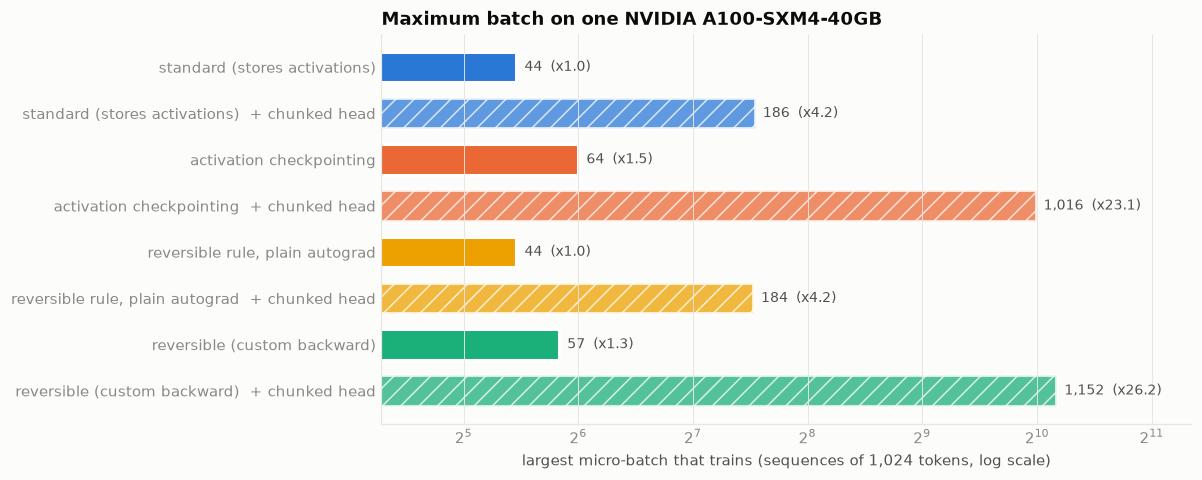

In [4]:
if CUDA:
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    names, vals, cols, hatch = [], [], [], []
    for mode, _ in MODES:
        for ce in (0, 4096):
            names.append(f"{viz.LABEL[mode]}{'  + chunked head' if ce else ''}")
            vals.append(maxb[(mode, ce)]['max_batch']); cols.append(viz.COLOR[mode]); hatch.append('//' if ce else '')
    y = np.arange(len(names))[::-1]
    bars = ax.barh(y, vals, color=cols, height=0.66, edgecolor='white', linewidth=2)
    for b, h_ in zip(bars, hatch):
        b.set_hatch(h_); b.set_alpha(0.75 if h_ else 1)
    for yi, v in zip(y, vals):
        ax.text(v, yi, f'  {v:,}  (x{v/maxb[("standard",0)]["max_batch"]:.1f})', va='center', fontsize=9, color=viz.INK2)
    ax.set_yticks(y, names); ax.set_xscale('log', base=2); ax.grid(axis='y', visible=False)
    ax.set_xlabel('largest micro-batch that trains (sequences of 1,024 tokens, log scale)')
    ax.set_title(f'Maximum batch on one {gpu_name(device())}'); ax.margins(x=0.25)
    viz.save(fig, '03_max_batch'); plt.show()

## 2 · Where the memory goes

Max-batch numbers hide the composition. Here is one training step at the fixed batch, split into its parts:

* **training state**: fp32 weights, gradients and two Adam moments, 16 bytes per parameter, measured as memory held before the step;
* **LM head**: the measured difference between the full-logit head and the chunked head;
* **residual stack**: everything else, which is what reversibility attacks.

[cache] composition: loaded from full/composition.json


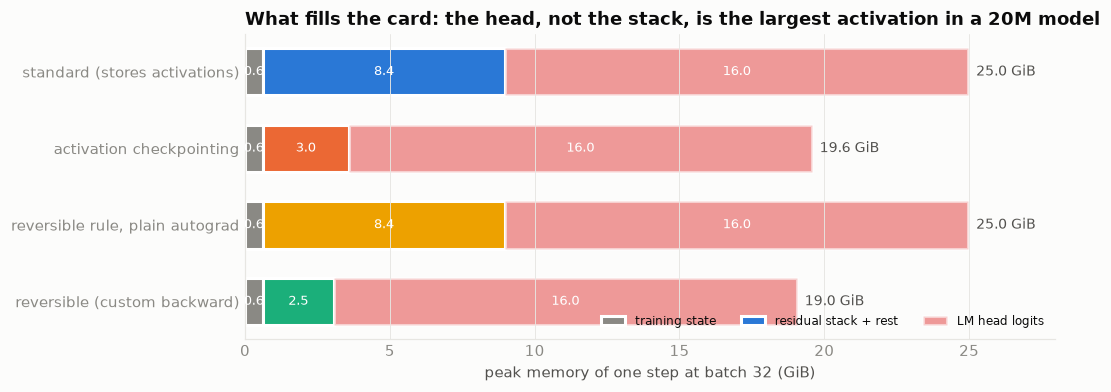

standard (stores activations)        state  0.60  stack+rest  8.39  head 15.97  GiB
activation checkpointing             state  0.60  stack+rest  2.99  head 15.97  GiB
reversible rule, plain autograd      state  0.60  stack+rest  8.39  head 15.98  GiB
reversible (custom backward)         state  0.60  stack+rest  2.47  head 15.97  GiB


In [5]:
if CUDA:
    comp = store.cached('composition', lambda: {f'{m}_ce{ce}': probe.step_peak(dict(B0, mode=m, ce_chunk=ce, **ex), FIXED_B)[0]
                                                for m, ex in MODES for ce in (0, 4096)})
    from s13.train import build
    n_par = build(dict(DEFAULTS, **B0), device()).n_params(False)
    state = n_par * 16
    fig, ax = plt.subplots(figsize=(9.5, 3.6))
    y = np.arange(len(MODES))[::-1]
    parts_all = []
    for yi, (m, _) in zip(y, MODES):
        full, chunk = comp[f'{m}_ce0'], comp[f'{m}_ce4096']
        parts = [state / GiB, max(0, chunk - state) / GiB, max(0, full - chunk) / GiB]
        parts_all.append((m, parts))
        left = 0
        for p, col, lab in zip(parts, ['#8a8984', viz.COLOR[m], '#e34948'], ['training state', 'residual stack + rest', 'LM head logits']):
            ax.barh(yi, p, left=left, color=col, height=0.62, edgecolor='white', linewidth=2, alpha=0.55 if lab == 'LM head logits' else 1,
                    label=lab if m == 'standard' else None)
            if p > 0.6:
                ax.text(left + p / 2, yi, f'{p:.1f}', ha='center', va='center', fontsize=8.5, color='white')
            left += p
        ax.text(left, yi, f'  {left:.1f} GiB', va='center', fontsize=9, color=viz.INK2)
    ax.set_yticks(y, [viz.LABEL[m] for m, _ in MODES]); ax.grid(axis='y', visible=False)
    ax.set_xlabel(f'peak memory of one step at batch {FIXED_B} (GiB)'); ax.legend(loc='lower right', ncol=3, fontsize=8)
    ax.set_title('What fills the card: the head, not the stack, is the largest activation in a 20M model'); ax.margins(x=0.12)
    viz.save(fig, '03_composition'); plt.show()
    for m, p in parts_all:
        print(f'{viz.LABEL[m]:<36} state {p[0]:5.2f}  stack+rest {p[1]:5.2f}  head {p[2]:5.2f}  GiB')

## 3 · Does a bigger batch buy speed?

The paper's throughput gain (114 vs 57 samples/s at 96 layers) comes from the larger batch that the saved memory allows. Here is tokens/s against batch for each configuration, measured over 4 steady-state steps.

[cache] throughput: loaded from full/throughput.json


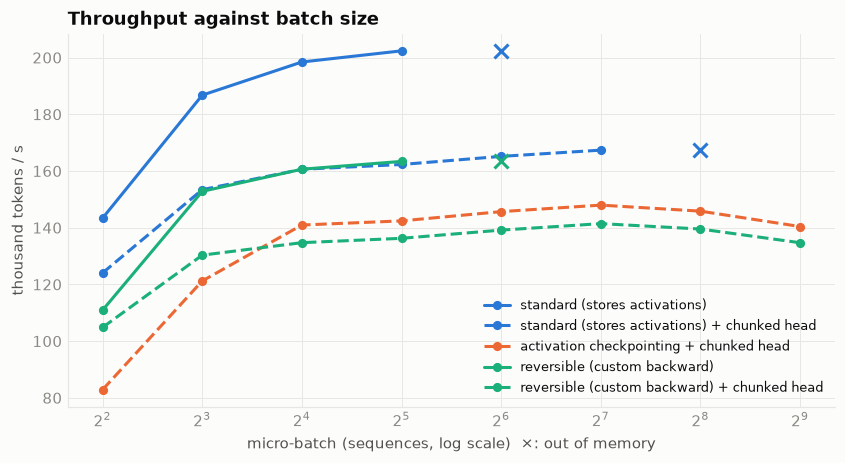

In [6]:
if CUDA:
    TP = [('standard', 0, {}), ('standard', 4096, {}), ('ckpt', 4096, {}), ('rev', 0, REV), ('rev', 4096, REV)]
    tput = store.cached('throughput', lambda: {f'{m}_ce{ce}': probe.throughput(dict(B0, mode=m, ce_chunk=ce, **ex), CFG['tput_batches'])
                                               for m, ce, ex in TP})
    fig, ax = plt.subplots(figsize=(9, 4.4))
    for m, ce, _ in TP:
        pts = [p for p in tput[f'{m}_ce{ce}'] if not p.get('oom')]
        ax.plot([p['batch'] for p in pts], [p['tok_per_s'] / 1e3 for p in pts], color=viz.COLOR[m], ls='--' if ce else '-',
                marker='o', ms=5, label=f"{viz.LABEL[m]}{' + chunked head' if ce else ''}")
        oom = [p for p in tput[f'{m}_ce{ce}'] if p.get('oom')]
        if oom:
            ax.plot([oom[0]['batch']], [pts[-1]['tok_per_s'] / 1e3], marker='x', color=viz.COLOR[m], ms=9, mew=2, ls='none')
    ax.set_xscale('log', base=2); ax.set_xlabel('micro-batch (sequences, log scale)  ×: out of memory'); ax.set_ylabel('thousand tokens / s')
    ax.set_title('Throughput against batch size'); ax.legend(fontsize=8.5)
    viz.save(fig, '03_throughput'); plt.show()

## 4 · Train at the maximum batch

All runs see the same 50M tokens. A larger batch means **fewer optimizer steps**: 50M tokens at 32 sequences is 1,525 steps, and at 512 sequences it is 95. So each max-batch configuration is trained twice:

* with the baseline's learning rate (2e-3),
* with the learning rate scaled by √(batch ratio), the usual rule for Adam, capped at 8e-3.

The standard model is also trained at *its* maximum batch, so the effect of reversibility is separated from the effect of a bigger batch.

The micro-batch is set to 97% of the probed maximum. The probe runs two steps, and a 50M-token run also has to survive evaluation passes and allocator fragmentation.

In [7]:
def lr_for(B, scale):
    return 2e-3 if not scale else min(8e-3, 2e-3 * math.sqrt(B / FIXED_B))

mb_runs = []
if CUDA:
    plan = [('std-max',       dict(mode='standard'),            maxb[('standard', 0)]['max_batch']),
            ('rev-max',       dict(mode='rev', **REV),          maxb[('rev', 0)]['max_batch']),
            ('rev-chunk-max', dict(mode='rev', ce_chunk=4096, **REV), maxb[('rev', 4096)]['max_batch'])]
else:
    plan = [('rev-max', dict(mode='rev', **REV), 8)]
for name, extra, bmax in plan:
    B = max(1, int(bmax * 0.97)) if CUDA else bmax
    for scale in (False, True):
        cfg = dict(B0, name=f"{name}{'-sqrtlr' if scale else ''}", batch=B, tokens=TOK, lr=lr_for(B, scale), **extra)
        mb_runs.append(store.cached(f"run_{cfg['name']}", lambda cfg=cfg: run(cfg)))
baseline = store.load('run_baseline')
winner_run = store.load(f"run_{W['name']}")
report.table([baseline, winner_run] + mb_runs)

[cache] run_std-max: loaded from full/run_std-max.json


[cache] run_std-max-sqrtlr: loaded from full/run_std-max-sqrtlr.json


[cache] run_rev-max: loaded from full/run_rev-max.json


[cache] run_rev-max-sqrtlr: loaded from full/run_rev-max-sqrtlr.json


[rev-chunk-max] 43 steps x 1,143,808 tok | mode=rev midpoint | NVIDIA A100-SXM4-40GB


[rev-chunk-max]    5.7M tok  train 9.1437  val 8.6759  0 tok/s


... (17 outputs left out)

[rev-chunk-max-sqrtlr]   40.0M tok  train 7.6690  val 7.7053  123,607 tok/s


[rev-chunk-max-sqrtlr]   45.8M tok  train 7.6565  val 7.6958  123,610 tok/s


[rev-chunk-max-sqrtlr] done: val 7.6856 | 123,611 tok/s | peak 35.05 GiB | 414s | $0.241


,what,batch (seq),tokens/step,steps,final val loss,final train loss,tokens/s,peak mem (GiB),wall (s),cost ($)
run,,,,,,,,,,
baseline,standard (stores activations),32,32768,1525,4.4480,4.3943,199981,24.96,265,0.155
rev-midpoint-nokick,"midpoint h=0.5, no-kick start",32,32768,1525,4.5064,4.4520,162562,19.05,322,0.188
std-max,standard (stores activations),42,43008,1162,4.4835,4.4318,204078,32.65,259,0.152
std-max-sqrtlr,standard (stores activations),42,43008,1162,4.5349,4.4833,204030,32.65,260,0.152
rev-max,"midpoint h=0.5, no-kick start",55,56320,887,4.7118,4.6602,166838,32.37,314,0.184
rev-max-sqrtlr,"midpoint h=0.5, no-kick start",55,56320,887,5.1661,5.1056,166808,32.37,314,0.184
rev-chunk-max,"midpoint h=0.5, no-kick start + chunked head",1117,1143808,43,7.5572,7.5414,123548,35.05,414,0.242
rev-chunk-max-sqrtlr,"midpoint h=0.5, no-kick start + chunked head",1117,1143808,43,7.6856,7.6640,123610,35.05,413,0.241


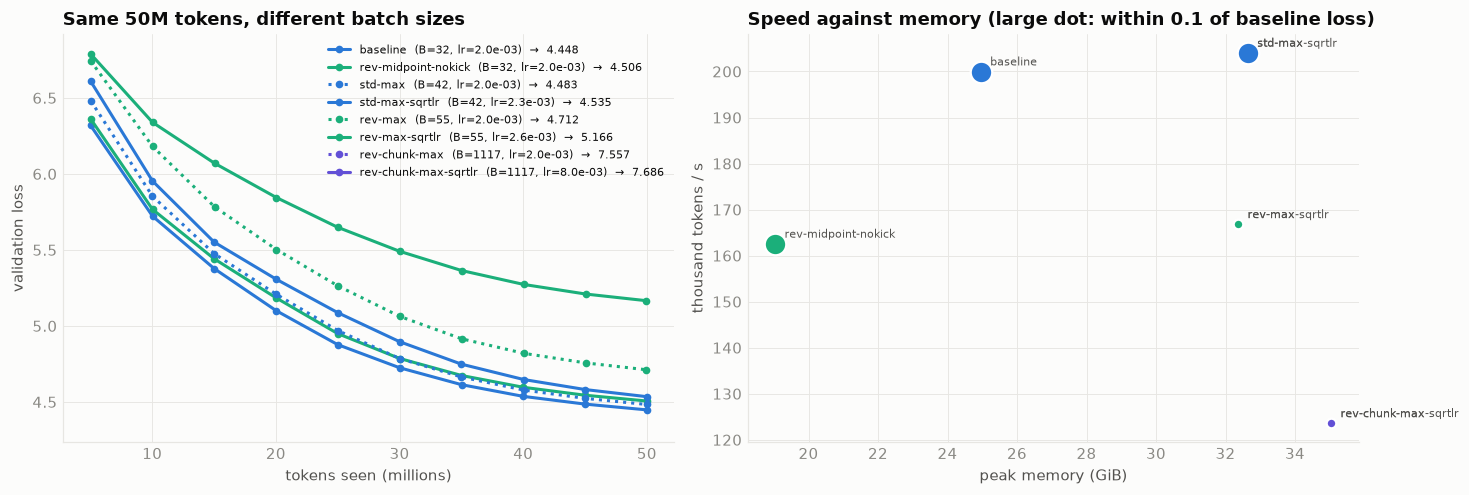

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
show = [baseline, winner_run] + mb_runs
cols = {r['cfg']['name']: c for r, c in zip(show, [viz.COLOR['standard'], viz.COLOR['rev'], viz.SLOTS[0], viz.SLOTS[0], viz.SLOTS[2], viz.SLOTS[2], viz.SLOTS[6], viz.SLOTS[6]])}
sty = {r['cfg']['name']: (':' if 'sqrtlr' not in r['cfg']['name'] and 'max' in r['cfg']['name'] else '-') for r in show}
for r in show:
    et = np.array(r['evals']['tokens']) / 1e6
    lab = f"{r['cfg']['name']}  (B={r['cfg']['batch']}, lr={r['cfg']['lr']:.1e})  →  {r['final_val']:.3f}"
    axes[0].plot(et, r['evals']['val'], color=cols[r['cfg']['name']], ls=sty[r['cfg']['name']], marker='o', ms=4, lw=2, label=lab)
axes[0].set_xlabel('tokens seen (millions)'); axes[0].set_ylabel('validation loss'); axes[0].legend(fontsize=7.5)
axes[0].set_title('Same 50M tokens, different batch sizes'); axes[0].set_ylim(top=min(8, max(baseline['evals']['val']) + 0.6))
for r in show:
    axes[1].scatter(r['peak_mem_bytes'] / GiB, r['tok_per_s'] / 1e3, s=40 + 160 * (r['final_val'] < baseline['final_val'] + 0.1),
                    color=cols[r['cfg']['name']], edgecolor='white', linewidth=1.5, zorder=3)
    axes[1].annotate(r['cfg']['name'], (r['peak_mem_bytes'] / GiB, r['tok_per_s'] / 1e3), xytext=(6, 4), textcoords='offset points', fontsize=7.5, color=viz.INK2)
axes[1].set_xlabel('peak memory (GiB)'); axes[1].set_ylabel('thousand tokens / s'); axes[1].set_title('Speed against memory (large dot: within 0.1 of baseline loss)')
fig.tight_layout(); viz.save(fig, '03_maxbatch_runs'); plt.show()

In [9]:
print(f"{'run':<22}{'batch':>7}{'steps':>7}{'val':>9}{'Δ vs base':>11}{'tok/s':>11}{'peak GiB':>10}{'$':>8}")
for r in [baseline, winner_run] + mb_runs:
    print(f"{r['cfg']['name']:<22}{r['cfg']['batch']:>7}{r['steps']:>7}{r['final_val']:>9.4f}{r['final_val']-baseline['final_val']:>+11.4f}"
          f"{r['tok_per_s']:>11,.0f}{r['peak_mem_bytes']/GiB:>10.2f}{r['cost_usd']:>8.3f}")

run                     batch  steps      val  Δ vs base      tok/s  peak GiB       $
baseline                   32   1525   4.4480    +0.0000    199,982     24.96   0.155
rev-midpoint-nokick        32   1525   4.5064    +0.0584    162,563     19.05   0.188
std-max                    42   1162   4.4835    +0.0355    204,079     32.65   0.152
std-max-sqrtlr             42   1162   4.5349    +0.0869    204,031     32.65   0.152
rev-max                    55    887   4.7118    +0.2638    166,839     32.37   0.184
rev-max-sqrtlr             55    887   5.1661    +0.7181    166,809     32.37   0.184
rev-chunk-max            1117     43   7.5572    +3.1092    123,548     35.05   0.242
rev-chunk-max-sqrtlr     1117     43   7.6856    +3.2376    123,611     35.05   0.241
